## Práctica

Puedes utilizar este notebook para analisar el dataset propuesto

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

In [2]:
datos = fetch_california_housing()
df_california = pd.DataFrame(datos.data, columns=datos.feature_names)
df_california['MedHouseVal'] = datos.target
df_california.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


##### Tipos de datos y faltantes

In [3]:
print(df_california.dtypes)
print(df_california.isnull().sum())

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


##### Estadisticos

In [4]:
df_california.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


##### Filtro, con valores fijos

In [5]:
df_filtrado = df_california[(df_california['HouseAge'] >= 10) &
                            (df_california['HouseAge'] <= 30) &
                            (df_california['Latitude'] >= 37)]
print('Filas:', len(df_filtrado))
print('Mediana:', df_filtrado['MedHouseVal'].median())
print('Rango:', df_filtrado['MedHouseVal'].max() - df_filtrado['MedHouseVal'].min())

Filas: 3703
Mediana: 1.601
Rango: 4.85002


##### Histograma y dispersión

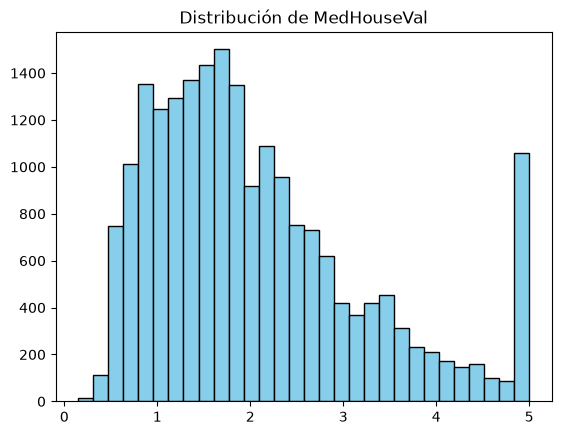

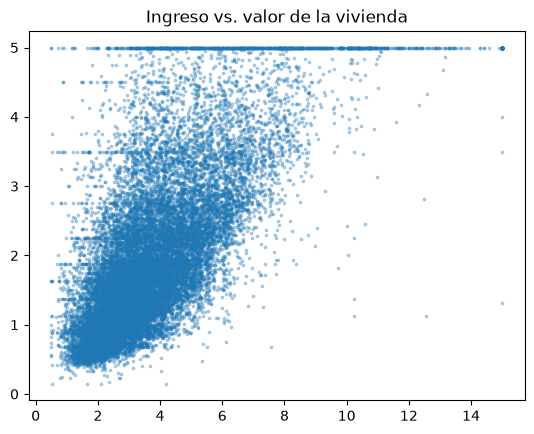

In [6]:
fig, ax = plt.subplots()
ax.hist(df_california['MedHouseVal'], bins=30, color='skyblue', edgecolor='black')
ax.set_title('Distribución de MedHouseVal')
plt.show()

fig, ax = plt.subplots()
ax.scatter(df_california['MedInc'], df_california['MedHouseVal'], s=3, alpha=0.3)
ax.set_title('Ingreso vs. valor de la vivienda')
plt.show()

##### Observaciones
No hay valores faltantes y todas las columnas son numéricas (float64).
El valor de las viviendas está sesgado a la derecha y topeado en 5 (USD 500.000).
El ingreso y el valor tienen una relación positiva fuerte (correlación cercana a 0.7–0.8).